In [1]:
import sys, json, warnings, io, unittest
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.evaluation import intervals as V
from src.evaluation.run_feature_selection import load

pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True); TAB = ROOT / 'reports' / 'tables'
V.run_all()                                           # no-op when the cache exists
df, X, y, folds = load()
D = pd.read_csv(V.OUT / 'cv_intervals.csv.gz'); DR = pd.read_csv(V.OUT / 'cv_intervals_regularised.csv.gz')
TM = pd.read_csv(V.OUT / 'temporal_intervals.csv.gz'); TMR = pd.read_csv(V.OUT / 'temporal_intervals_regularised.csv.gz')
META = json.loads((V.OUT / 'run_metadata.json').read_text())
feat = df[['Id', 'Neighborhood', 'YearBuilt', 'GrLivArea', 'YrSold']].reset_index().rename(columns={'index': 'row'})
D = D.merge(feat.drop(columns='Id'), on='row')
D['age'] = 2010 - D.YearBuilt
D['seg_actual'] = pd.cut(D.y, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
D['seg_pred'] = pd.cut(D.point, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
D['age_group'] = pd.cut(D.age, [-1, 10, 30, 60, 1000], labels=['<=10 yr', '11-30 yr', '31-60 yr', '>60 yr'])
D['area_group'] = pd.cut(D.GrLivArea, [0, 1200, 1800, 1e6], right=True, labels=['<=1,200 sq ft', '1,201-1,800', '>1,800 sq ft'])
D['flagged'] = D.Id.isin(V.FLAGGED_IDS)
R0 = D[D.repeat == 0]
NAME = {'raw': 'Quantile GB', 'cqr': 'CQR'}
print(len(D), 'evaluation predictions =', D.row.nunique(), 'houses x 3 CV repeats | experiment', META['experiment_id'], '| runtime', META['runtime_seconds'], 's')

4380 evaluation predictions = 1460 houses x 3 CV repeats | experiment intervals_v1 | runtime 32.6 s


In [2]:
rows = []
for n in [0, 1, 3, 4, 9, 19, 99, 100, 292]:
    q, k = V.conformal_quantile(np.arange(1, n + 1), 0.2)
    rows.append(dict(n_cal=n, k=k, naive_float_ceil=int(np.ceil((n + 1) * 0.8)), q_hat_for_scores_1_to_n='+inf (k > n)' if np.isinf(q) else q))
display(pd.DataFrame(rows).set_index('n_cal'))
print('k uses exact rational arithmetic: for n = 9, (n+1)*0.8 = 8 exactly, but float arithmetic can give 8.000000000000002 and a naive ceil returns 9.')
print('Realised calibration sizes:', sorted(D.n_cal.unique()), '| k =', V.conformal_k(int(D.n_cal.iloc[0])), '| q_hat on the log1p scale: mean %.4f, min %.4f, max %.4f over the 15 folds' % (D.groupby('fold').q_hat.first().mean(), D.groupby('fold').q_hat.first().min(), D.groupby('fold').q_hat.first().max()))
print('Quantile crossings per fold (calibration set / evaluation set):', int(D.groupby('fold').cross_cal.first().sum()), '/', int(D.groupby('fold').cross_eval.first().sum()), 'in total over 15 folds (rearranged by sorting)')

,k,naive_float_ceil,q_hat_for_scores_1_to_n
n_cal,,,
0,1,1,+inf (k > n)
1,2,2,+inf (k > n)
3,4,4,+inf (k > n)
4,4,4,4.0
9,8,8,8.0
19,16,16,16.0
99,80,80,80.0
100,81,81,81.0
292,235,235,235.0


k uses exact rational arithmetic: for n = 9, (n+1)*0.8 = 8 exactly, but float arithmetic can give 8.000000000000002 and a naive ceil returns 9.
Realised calibration sizes: [np.int64(292)] | k = 235 | q_hat on the log1p scale: mean 0.0381, min 0.0251, max 0.0490 over the 15 folds
Quantile crossings per fold (calibration set / evaluation set): 4 / 3 in total over 15 folds (rearranged by sorting)


In [3]:
def main_table(d):
    rows = {}
    for m in ['raw', 'cqr']:
        t = V.metrics_over_repeats(d, m).iloc[0]
        rows[NAME[m]] = {'Nominal coverage': '80%', 'Empirical coverage': t.coverage, '95% CI (houses, repeat 0)': f'{t.cov_ci_lo:.3f} to {t.cov_ci_hi:.3f}', 'Coverage gap (pp)': t.coverage_gap_pp,
                         'Mean width USD': t.mean_width_usd, 'Median width USD': t.median_width_usd, 'Median relative width %': t.median_rel_width_pct,
                         'Mean interval score USD': t.mean_winkler_usd, 'SD of coverage over repeats': t.coverage_sd_over_repeats}
    return pd.DataFrame(rows).T
MT = main_table(D)
display(MT.assign(**{'Empirical coverage': MT['Empirical coverage'].astype(float).round(4), 'Coverage gap (pp)': MT['Coverage gap (pp)'].astype(float).round(2), 'Mean width USD': MT['Mean width USD'].astype(float).round(0), 'Median width USD': MT['Median width USD'].astype(float).round(0),
                     'Median relative width %': MT['Median relative width %'].astype(float).round(1), 'Mean interval score USD': MT['Mean interval score USD'].astype(float).round(0), 'SD of coverage over repeats': MT['SD of coverage over repeats'].astype(float).round(4)}))
MT.to_csv(TAB / 'intervals_main_comparison.csv')
print('Both methods use the SAME base quantile models, the SAME 1,460 evaluation houses per repeat and the SAME point predictions.')
fc = D.groupby('fold').agg(raw=('cover_raw', 'mean'), cqr=('cover_cqr', 'mean'))
print('Fold-level coverage (15 folds of about 292 houses): quantile GB mean %.3f (SD %.3f, range %.3f-%.3f); CQR mean %.3f (SD %.3f, range %.3f-%.3f)' % (fc.raw.mean(), fc.raw.std(), fc.raw.min(), fc.raw.max(), fc.cqr.mean(), fc.cqr.std(), fc.cqr.min(), fc.cqr.max()))
print('Raw quantile coverage on the calibration sets themselves (out-of-sample for the base models): mean %.3f' % D.groupby('fold').raw_cal_coverage.first().mean())
print('Where the missed prices fall (share of evaluation houses): '); display(pd.DataFrame({NAME[m]: D[f'miss_{m}'].value_counts(normalize=True) for m in ['raw', 'cqr']}).T.round(3))
pin = pd.DataFrame({NAME[m]: {'point prediction outside the interval (share)': float(((D.point < D[f'lo_{m}']) | (D.point > D[f'hi_{m}'])).mean())} for m in ['raw', 'cqr']}).T
print('Consistency of the point model and the interval models (the point prediction is NOT forced inside the interval):'); display(pin.round(4))
print('Sensitivity (pre-specified smoother base models, reported separately, never used to choose the primary configuration):')
display(main_table(DR)[['Empirical coverage', 'Coverage gap (pp)', 'Mean width USD', 'Median relative width %', 'Mean interval score USD']].astype(float).round({'Empirical coverage': 4, 'Coverage gap (pp)': 2, 'Mean width USD': 0, 'Median relative width %': 1, 'Mean interval score USD': 0}))

,Nominal coverage,Empirical coverage,"95% CI (houses, repeat 0)",Coverage gap (pp),Mean width USD,Median width USD,Median relative width %,Mean interval score USD,SD of coverage over repeats
Quantile GB,80%,0.6511,0.640 to 0.689,-14.89,43161.0,31477.0,19.3,90321.0,0.0129
CQR,80%,0.8071,0.775 to 0.816,0.71,56702.0,43568.0,27.0,85156.0,0.0100


Both methods use the SAME base quantile models, the SAME 1,460 evaluation houses per repeat and the SAME point predictions.
Fold-level coverage (15 folds of about 292 houses): quantile GB mean 0.651 (SD 0.030, range 0.596-0.699); CQR mean 0.807 (SD 0.018, range 0.774-0.829)
Raw quantile coverage on the calibration sets themselves (out-of-sample for the base models): mean 0.647
Where the missed prices fall (share of evaluation houses): 


,inside,above,below
Quantile GB,0.651,0.183,0.166
CQR,0.807,0.097,0.096


Consistency of the point model and the interval models (the point prediction is NOT forced inside the interval):


,point prediction outside the interval (share)
Quantile GB,0.1290
CQR,0.0354


Sensitivity (pre-specified smoother base models, reported separately, never used to choose the primary configuration):


,Empirical coverage,Coverage gap (pp),Mean width USD,Median relative width %,Mean interval score USD
Quantile GB,0.7904,-0.96,70789.0,34.2,105499.0
CQR,0.8018,0.18,72611.0,35.3,105388.0


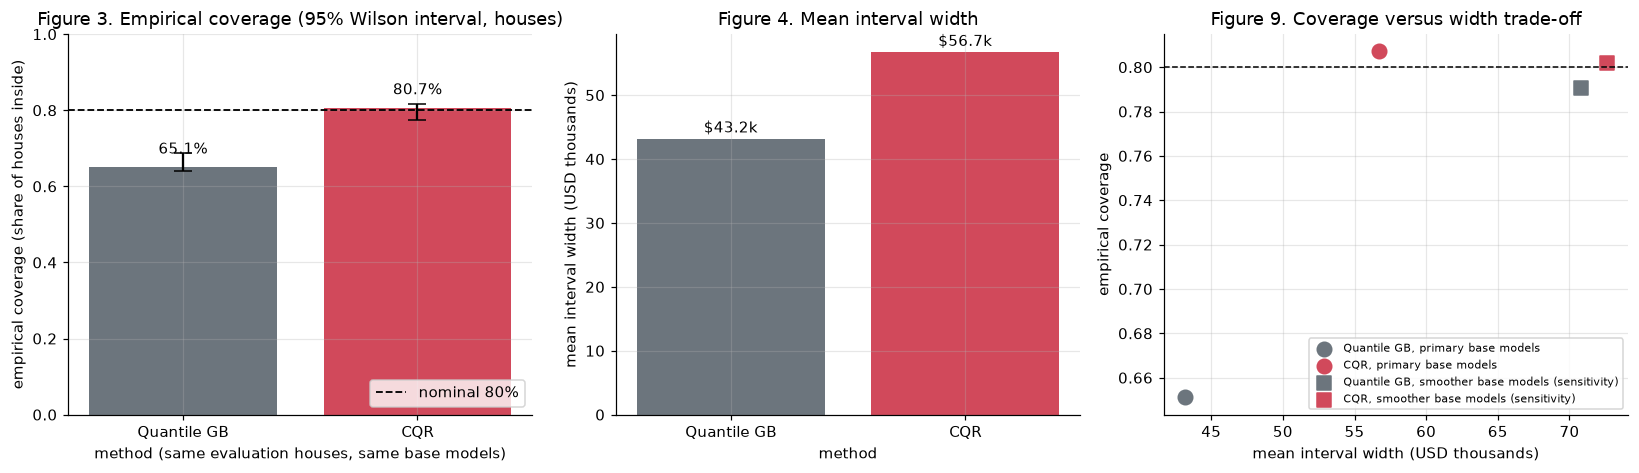

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
meths = ['raw', 'cqr']; cols = {'raw': '#6c757d', 'cqr': '#d1495b'}
mt = {m: V.metrics_over_repeats(D, m).iloc[0] for m in meths}; mr = {m: V.metrics_over_repeats(DR, m).iloc[0] for m in meths}
x = np.arange(2)
cov = [mt[m].coverage for m in meths]; err = [[mt[m].coverage - mt[m].cov_ci_lo for m in meths], [mt[m].cov_ci_hi - mt[m].coverage for m in meths]]
axes[0].bar(x, cov, yerr=err, color=[cols[m] for m in meths], capsize=6); axes[0].axhline(.8, color='k', ls='--', lw=1.2, label='nominal 80%')
for i, m in enumerate(meths): axes[0].text(i, cov[i] + .035, f'{cov[i]:.1%}', ha='center')
axes[0].set_xticks(x); axes[0].set_xticklabels([NAME[m] for m in meths]); axes[0].set_ylim(0, 1); axes[0].set_ylabel('empirical coverage (share of houses inside)'); axes[0].set_xlabel('method (same evaluation houses, same base models)')
axes[0].set_title('Figure 3. Empirical coverage (95% Wilson interval, houses)'); axes[0].legend(loc='lower right')
w = [mt[m].mean_width_usd / 1e3 for m in meths]
axes[1].bar(x, w, color=[cols[m] for m in meths]); [axes[1].text(i, w[i] + 1, f'${w[i]:.1f}k', ha='center') for i in range(2)]
axes[1].set_xticks(x); axes[1].set_xticklabels([NAME[m] for m in meths]); axes[1].set_ylabel('mean interval width (USD thousands)'); axes[1].set_xlabel('method'); axes[1].set_title('Figure 4. Mean interval width')
for lab, tab, mk in [('primary base models', mt, 'o'), ('smoother base models (sensitivity)', mr, 's')]:
    for m in meths: axes[2].scatter(tab[m].mean_width_usd / 1e3, tab[m].coverage, s=90, marker=mk, color=cols[m], label=f'{NAME[m]}, {lab}')
axes[2].axhline(.8, color='k', ls='--', lw=1); axes[2].set_xlabel('mean interval width (USD thousands)'); axes[2].set_ylabel('empirical coverage'); axes[2].set_title('Figure 9. Coverage versus width trade-off'); axes[2].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.savefig(FIG / 'intervals_fig3_4_9.png'); plt.show()

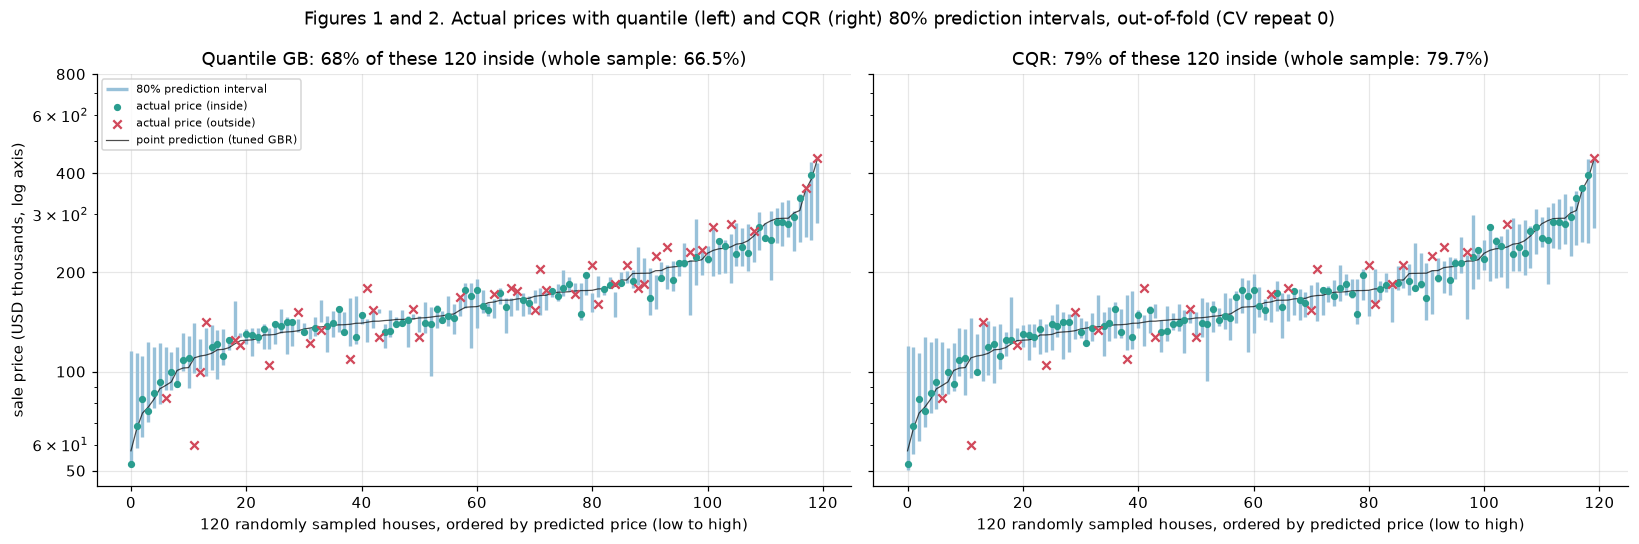

In [5]:
rng = np.random.default_rng(0)
samp = R0.iloc[rng.choice(len(R0), 120, replace=False)].sort_values('point').reset_index(drop=True)     # random sample (seed 0), not selected on outcome
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, m in zip(axes, meths):
    inside = samp[f'cover_{m}']
    ax.vlines(samp.index, samp[f'lo_{m}'] / 1e3, samp[f'hi_{m}'] / 1e3, color='#98c1d9', lw=2.2, label='80% prediction interval')
    ax.scatter(samp.index[inside], samp.y[inside] / 1e3, s=14, color='#2a9d8f', label='actual price (inside)', zorder=3)
    ax.scatter(samp.index[~inside], samp.y[~inside] / 1e3, s=30, color='#d1495b', marker='x', label='actual price (outside)', zorder=3)
    ax.plot(samp.index, samp.point / 1e3, color='k', lw=.8, alpha=.7, label='point prediction (tuned GBR)')
    ax.set_yscale('log'); ax.set_yticks([50, 100, 200, 400, 800]); ax.set_yticklabels([50, 100, 200, 400, 800]); ax.set_xlabel('120 randomly sampled houses, ordered by predicted price (low to high)')
    ax.set_title(f'{NAME[m]}: {inside.mean():.0%} of these 120 inside (whole sample: {R0[f"cover_{m}"].mean():.1%})')
axes[0].set_ylabel('sale price (USD thousands, log axis)'); axes[0].legend(fontsize=7, loc='upper left')
fig.suptitle('Figures 1 and 2. Actual prices with quantile (left) and CQR (right) 80% prediction intervals, out-of-fold (CV repeat 0)')
plt.tight_layout(); plt.savefig(FIG / 'intervals_fig1_2_samples.png'); plt.show()

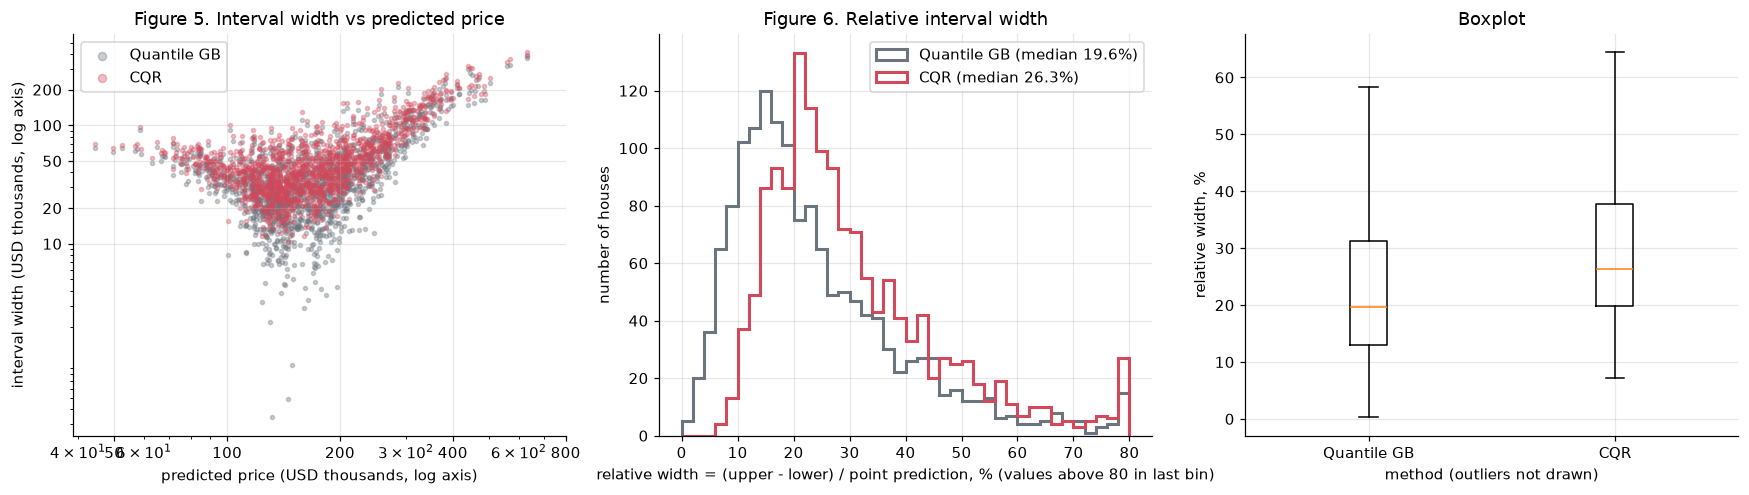

Width as a share of predicted price, by predicted-price band (median %):


,Quantile GB,CQR
seg_pred,,
low,29.7,36.2
mid,16.3,22.9
luxury,36.5,43.0


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for m in meths: axes[0].scatter(R0.point / 1e3, R0[f'width_{m}'] / 1e3, s=7, alpha=.35, color=cols[m], label=NAME[m])
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xticks([50, 100, 200, 400, 800]); axes[0].set_xticklabels([50, 100, 200, 400, 800]); axes[0].set_yticks([10, 20, 50, 100, 200]); axes[0].set_yticklabels([10, 20, 50, 100, 200])
axes[0].set_xlabel('predicted price (USD thousands, log axis)'); axes[0].set_ylabel('interval width (USD thousands, log axis)'); axes[0].set_title('Figure 5. Interval width vs predicted price'); axes[0].legend(markerscale=2)
bins = np.linspace(0, 80, 41)
for m in meths: axes[1].hist(np.clip(100 * R0[f'relwidth_{m}'], 0, 80), bins=bins, histtype='step', lw=2, color=cols[m], label=f"{NAME[m]} (median {100 * R0[f'relwidth_{m}'].median():.1f}%)")
axes[1].set_xlabel('relative width = (upper - lower) / point prediction, % (values above 80 in last bin)'); axes[1].set_ylabel('number of houses'); axes[1].set_title('Figure 6. Relative interval width'); axes[1].legend()
axes[2].boxplot([100 * R0[f'relwidth_{m}'] for m in meths], showfliers=False); axes[2].set_xticks([1, 2]); axes[2].set_xticklabels([NAME[m] for m in meths]); axes[2].set_ylabel('relative width, %'); axes[2].set_xlabel('method (outliers not drawn)'); axes[2].set_title('Boxplot')
plt.tight_layout(); plt.savefig(FIG / 'intervals_fig5_6_width.png'); plt.show()
print('Width as a share of predicted price, by predicted-price band (median %):'); display(R0.groupby('seg_pred', observed=True)[['relwidth_raw', 'relwidth_cqr']].median().mul(100).round(1).rename(columns={'relwidth_raw': 'Quantile GB', 'relwidth_cqr': 'CQR'}))

In [7]:
def seg_table(d, col, min_n=0):
    out = []
    for m in meths:
        t = V.metrics_over_repeats(d, m, by=col)
        r0 = d[d.repeat == 0].groupby(col, observed=True)[f'cover_{m}'].agg(['sum', 'count'])
        t['p_below_80'] = [stats.binomtest(int(r0.loc[i, 'sum']), int(r0.loc[i, 'count']), 0.8, alternative='less').pvalue for i in t.index]
        t['method'] = NAME[m]; out.append(t.reset_index())
    t = pd.concat(out); k = t[col].nunique()
    t['persuasive?'] = np.where(t.p_below_80 < 0.05 / k, 'yes', 'no')
    t['small (n<50)'] = np.where(t.n < 50, 'small', '')
    keep = ['method', col, 'n', 'coverage', 'cov_ci_lo', 'cov_ci_hi', 'coverage_gap_pp', 'mean_width_usd', 'median_rel_width_pct', 'p_below_80', 'persuasive?', 'small (n<50)']
    t = t[keep]
    return t[t.n >= min_n].set_index(['method', col]).sort_index()
fmt = {'n': 0, 'coverage': 3, 'cov_ci_lo': 3, 'cov_ci_hi': 3, 'coverage_gap_pp': 1, 'mean_width_usd': 0, 'median_rel_width_pct': 1, 'p_below_80': 4}
SEGS = {}
for lab, col in [('Retrospective: actual-price band', 'seg_actual'), ('Deployable: predicted-price band', 'seg_pred'), ('Property-age group', 'age_group'), ('Living-area group', 'area_group')]:
    SEGS[col] = seg_table(D, col); print(lab); display(SEGS[col].round(fmt)); SEGS[col].round(4).to_csv(TAB / f'intervals_segments_{col}.csv')

Retrospective: actual-price band


n  coverage  cov_ci_lo  cov_ci_hi  coverage_gap_pp  mean_width_usd  median_rel_width_pct  p_below_80 persuasive? small (n<50)
method      seg_actual                                                                                                                                   
CQR         low         365.0     0.755      0.707      0.795             -4.5         41507.0                  35.2      0.0172          no             
            luxury      144.0     0.720      0.608      0.758             -8.0        147817.0                  42.7      0.0009         yes             
            mid         951.0     0.840      0.804      0.852              4.0         48738.0                  23.8      0.9910          no             
Quantile GB low         365.0     0.652      0.605      0.702            -14.8         32464.0                  27.3      0.0000         yes             
            luxury      144.0     0.602      0.523      0.680            -19.8        124687.0                  34.9      0.0000         yes             
            mid         951.0     0.658      0.648      0.707            -14.2         34922.0                  16.1      0.0000         yes

Deployable: predicted-price band


n  coverage  cov_ci_lo  cov_ci_hi  coverage_gap_pp  mean_width_usd  median_rel_width_pct  p_below_80 persuasive? small (n<50)
method      seg_pred                                                                                                                                   
CQR         low       371.0     0.809      0.778      0.856              0.9         41857.0                  36.1      0.8490          no             
            luxury    142.0     0.784      0.693      0.832             -1.6        156592.0                  43.3      0.2139          no             
            mid       947.0     0.810      0.764      0.816              1.0         47546.0                  23.5      0.2649          no             
Quantile GB low       371.0     0.708      0.680      0.771             -9.2         32937.0                  28.0      0.0005         yes             
            luxury    142.0     0.688      0.610      0.761            -11.2        132870.0                  36.2      0.0015         yes             
            mid       947.0     0.623      0.606      0.667            -17.7         33722.0                  15.9      0.0000         yes

Property-age group


n  coverage  cov_ci_lo  cov_ci_hi  coverage_gap_pp  mean_width_usd  median_rel_width_pct  p_below_80 persuasive? small (n<50)
method      age_group                                                                                                                                   
CQR         11-30 yr   224.0     0.833      0.751      0.854              3.3         59282.0                  23.1      0.6442          no             
            31-60 yr   530.0     0.811      0.776      0.842              1.1         43257.0                  25.4      0.7581          no             
            <=10 yr    388.0     0.817      0.748      0.829              1.7         76224.0                  25.2      0.3524          no             
            >60 yr     318.0     0.770      0.721      0.813             -3.0         53475.0                  37.8      0.1073          no             
Quantile GB 11-30 yr   224.0     0.610      0.583      0.707            -19.0         43338.0                  15.5      0.0000         yes             
            31-60 yr   530.0     0.666      0.658      0.736            -13.4         31799.0                  17.9      0.0000         yes             
            <=10 yr    388.0     0.643      0.580      0.675            -15.7         58653.0                  17.6      0.0000         yes             
            >60 yr     318.0     0.666      0.613      0.716            -13.4         43072.0                  29.8      0.0000         yes

Living-area group


n  coverage  cov_ci_lo  cov_ci_hi  coverage_gap_pp  mean_width_usd  median_rel_width_pct  p_below_80 persuasive? small (n<50)
method      area_group                                                                                                                                      
CQR         1,201-1,800    685.0     0.792      0.752      0.813             -0.8         47837.0                  24.7      0.1579          no             
            <=1,200 sq ft  435.0     0.837      0.792      0.862              3.7         35352.0                  25.4      0.9494          no             
            >1,800 sq ft   340.0     0.800      0.732      0.820             -0.0        101880.0                  35.7      0.1882          no             
Quantile GB 1,201-1,800    685.0     0.619      0.609      0.680            -18.1         34308.0                  16.9      0.0000         yes             
            <=1,200 sq ft  435.0     0.685      0.652      0.738            -11.5         25830.0                  17.4      0.0000         yes             
            >1,800 sq ft   340.0     0.673      0.613      0.713            -12.7         83172.0                  27.9      0.0000         yes

In [8]:
D['nbhd'] = D.Neighborhood
big = R0.Neighborhood.value_counts(); keepN = big[big >= 50].index.tolist() + [n for n in ['StoneBr'] if n not in big[big >= 50].index]
NB = seg_table(D[D.Neighborhood.isin(keepN)].assign(nbhd=lambda d: d.Neighborhood), 'nbhd')
print('Neighbourhoods with >= 50 houses, plus StoneBr (n = 25, flagged small because the brief names it):'); display(NB.round(fmt)); NB.round(4).to_csv(TAB / 'intervals_segments_neighborhood.csv')

Neighbourhoods with >= 50 houses, plus StoneBr (n = 25, flagged small because the brief names it):


n  coverage  cov_ci_lo  cov_ci_hi  coverage_gap_pp  mean_width_usd  median_rel_width_pct  p_below_80 persuasive? small (n<50)
method      nbhd                                                                                                                                      
CQR         BrkSide   58.0     0.793      0.653      0.864             -0.7         41984.0                  31.2      0.3725          no             
            CollgCr  150.0     0.867      0.766      0.884              6.7         45352.0                  20.8      0.8706          no             
            Crawfor   51.0     0.693      0.570      0.813            -10.7         77597.0                  35.2      0.0707          no             
            Edwards  100.0     0.747      0.668      0.833             -5.3         55461.0                  35.1      0.1891          no             
            Gilbert   79.0     0.844      0.724      0.891              4.4         39804.0                  18.2      0.7356          no             
            NAmes    225.0     0.840      0.782      0.878              4.0         40606.0                  24.2      0.9245          no             
            NWAmes    73.0     0.840      0.766      0.924              4.0         53076.0                  25.2      0.9379          no             
            NridgHt   77.0     0.814      0.689      0.868              1.4        127203.0                  37.0      0.4772          no             
            OldTown  113.0     0.796      0.703      0.853             -0.4         51360.0                  37.8      0.4075          no             
            Sawyer    74.0     0.829      0.707      0.884              2.9         35169.0                  23.1      0.6376          no             
            SawyerW   59.0     0.847      0.677      0.880              4.7         48037.0                  22.3      0.5258          no             
            Somerst   86.0     0.783      0.668      0.844             -1.7         61669.0                  24.9      0.2622          no             
            StoneBr   25.0     0.707      0.484      0.828             -9.3        110220.0                  31.4      0.1091          no        small
Quantile GB BrkSide   58.0     0.655      0.527      0.764            -14.5         32373.0                  23.2      0.0071          no             
            CollgCr  150.0     0.667      0.588      0.737            -13.3         30388.0                  13.2      0.0001         yes             
            Crawfor   51.0     0.569      0.471      0.730            -23.1         63161.0                  27.9      0.0012         yes             
            Edwards  100.0     0.633      0.573      0.754            -16.7         44951.0                  27.2      0.0016         yes             
            Gilbert   79.0     0.578      0.485      0.696            -22.2         25445.0                  11.1      0.0000         yes             
            NAmes    225.0     0.696      0.672      0.787            -10.4         29322.0                  16.6      0.0095          no             
            NWAmes    73.0     0.680      0.644      0.838            -12.0         38668.0                  17.6      0.1957          no             
            NridgHt   77.0     0.680      0.565      0.769            -12.0        105321.0                  30.0      0.0068          no             
            OldTown  113.0     0.681      0.600      0.768            -11.9         40838.0                  29.8      0.0038         yes             
            Sawyer    74.0     0.662      0.591      0.795            -13.8         24724.0                  15.6      0.0299          no             
            SawyerW   59.0     0.638      0.466      0.709            -16.2         33679.0                  14.8      0.0002         yes             
            Somerst   86.0     0.624      0.522      0.723            -17.6         45274.0        

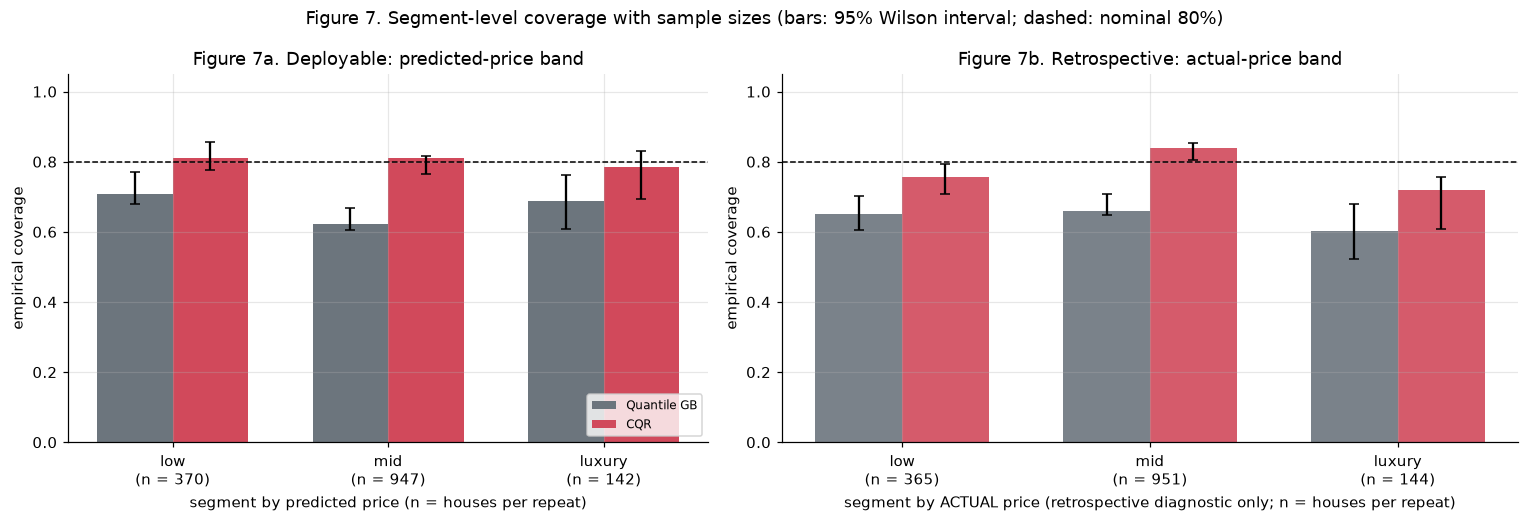

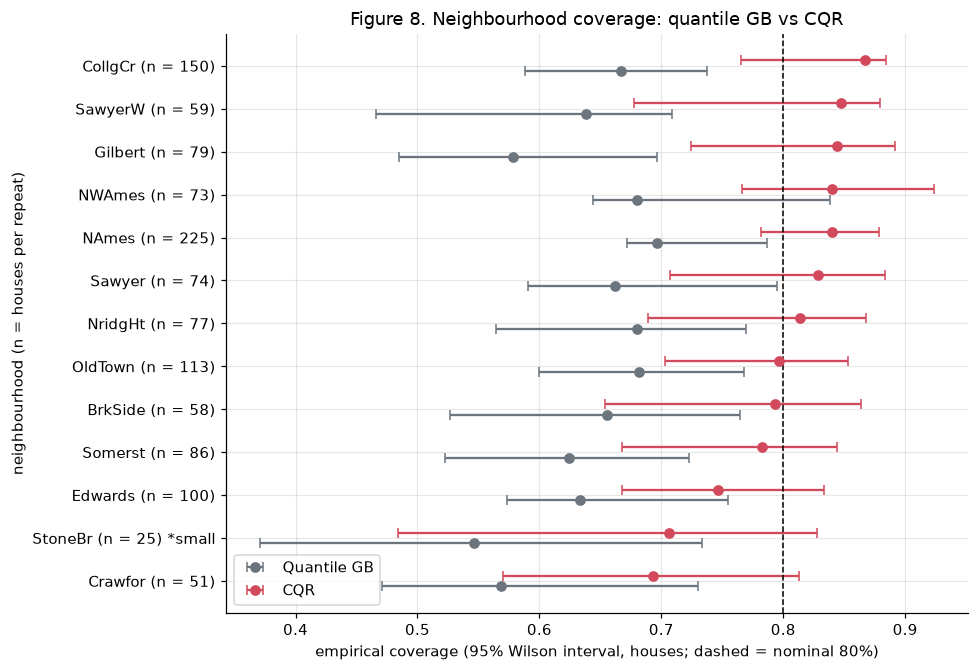

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1.15]})
order = ['low', 'mid', 'luxury']
w = .35
for ax, col, ttl in [(axes[0], 'seg_pred', 'Deployable: predicted-price band')]:
    t = SEGS[col]
    for k, m in enumerate(meths):
        s = t.loc[NAME[m]].loc[order]
        ax.bar(np.arange(3) + (k - .5) * w, s.coverage, w, color=cols[m], label=NAME[m], yerr=[s.coverage - s.cov_ci_lo, s.cov_ci_hi - s.coverage], capsize=3)
    ax.axhline(.8, color='k', ls='--', lw=1); ax.set_xticks(range(3)); ax.set_xticklabels([f"{o}\n(n = {int(SEGS['seg_pred'].loc[(NAME['cqr'], o), 'n'])})" for o in order]); ax.set_ylim(0, 1.05)
    ax.set_ylabel('empirical coverage'); ax.set_xlabel('segment by predicted price (n = houses per repeat)'); ax.set_title('Figure 7a. ' + ttl); ax.legend(loc='lower right', fontsize=8)
t = SEGS['seg_actual']; ax2 = axes[1]
for k, m in enumerate(meths):
    s = t.loc[NAME[m]].loc[order]
    ax2.bar(np.arange(3) + (k - .5) * w, s.coverage, w, color=cols[m], label=NAME[m], yerr=[s.coverage - s.cov_ci_lo, s.cov_ci_hi - s.coverage], capsize=3, alpha=.9)
ax2.axhline(.8, color='k', ls='--', lw=1); ax2.set_xticks(range(3)); ax2.set_xticklabels([f"{o}\n(n = {int(t.loc[(NAME['cqr'], o), 'n'])})" for o in order]); ax2.set_ylim(0, 1.05)
ax2.set_xlabel('segment by ACTUAL price (retrospective diagnostic only; n = houses per repeat)'); ax2.set_ylabel('empirical coverage'); ax2.set_title('Figure 7b. Retrospective: actual-price band')
fig.suptitle('Figure 7. Segment-level coverage with sample sizes (bars: 95% Wilson interval; dashed: nominal 80%)'); plt.tight_layout(); plt.savefig(FIG / 'intervals_fig7_segments.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 6.2))
nbo = NB.loc[NAME['cqr']].sort_values('coverage').index.tolist()
for k, m in enumerate(meths):
    s = NB.loc[NAME[m]].loc[nbo]
    ax.errorbar(s.coverage, np.arange(len(nbo)) + (k - .5) * .25, xerr=[s.coverage - s.cov_ci_lo, s.cov_ci_hi - s.coverage], fmt='o', color=cols[m], capsize=3, label=NAME[m])
ax.axvline(.8, color='k', ls='--', lw=1); ax.set_yticks(range(len(nbo))); ax.set_yticklabels([f"{n} (n = {int(NB.loc[(NAME['cqr'], n), 'n'])})" + (' *small' if NB.loc[(NAME['cqr'], n), 'n'] < 50 else '') for n in nbo])
ax.set_xlabel('empirical coverage (95% Wilson interval, houses; dashed = nominal 80%)'); ax.set_ylabel('neighbourhood (n = houses per repeat)'); ax.set_title('Figure 8. Neighbourhood coverage: quantile GB vs CQR'); ax.legend(loc='lower left')
plt.tight_layout(); plt.savefig(FIG / 'intervals_fig8_neighborhoods.png'); plt.show()

In [10]:
def group_row(d, mask, label):
    out = {}
    for m in meths:
        g = d[mask(d)]; per = g.groupby('repeat')[f'cover_{m}'].agg(['mean', 'sum', 'count']); r0 = per.loc[0]
        lo, hi = V.wilson(int(r0['sum']), int(r0['count']))
        out[NAME[m]] = dict(group=label, n_per_repeat=int(per['count'].mean()), coverage=per['mean'].mean(), ci=f'{lo:.2f} to {hi:.2f}', p_below_80=stats.binomtest(int(r0['sum']), int(r0['count']), .8, alternative='less').pvalue,
                            mean_width_usd=g[f'width_{m}'].mean(), median_rel_width_pct=100 * g[f'relwidth_{m}'].median())
    return out
rows = []
for label, mk in [('Luxury, by actual price (retrospective)', lambda d: d.seg_actual == 'luxury'), ('Luxury, by predicted price (deployable)', lambda d: d.seg_pred == 'luxury'),
                  ('Crawfor', lambda d: d.Neighborhood == 'Crawfor'), ('StoneBr (n = 25, small)', lambda d: d.Neighborhood == 'StoneBr'), ('Houses sold in 2010 (CV evaluation)', lambda d: d.YrSold == 2010),
                  ('Luxury (predicted) without flagged Ids', lambda d: (d.seg_pred == 'luxury') & ~d.flagged)]:
    r = group_row(D, mk, label)
    for m in r: rows.append({'method': m, **r[m]})
HG = pd.DataFrame(rows).set_index(['group', 'method']); display(HG.round({'coverage': 3, 'p_below_80': 4, 'mean_width_usd': 0, 'median_rel_width_pct': 1}))
HG.round(4).to_csv(TAB / 'intervals_historical_groups.csv')
print('Flagged houses (Ids 524, 1299): covered by raw / CQR intervals in repeat 0:', R0[R0.flagged][['Id', 'y', 'point', 'lo_cqr', 'hi_cqr', 'cover_raw', 'cover_cqr']].round(0).to_dict('records'))

n_per_repeat  coverage            ci  p_below_80  mean_width_usd  median_rel_width_pct
group                                   method                                                                                             
Luxury, by actual price (retrospective) Quantile GB           144     0.602  0.52 to 0.68      0.0000        124687.0                  35.2
                                        CQR                   144     0.720  0.61 to 0.76      0.0009        147817.0                  42.7
Luxury, by predicted price (deployable) Quantile GB           142     0.688  0.61 to 0.76      0.0015        132825.0                  36.1
                                        CQR                   142     0.784  0.69 to 0.83      0.2139        156579.0                  43.4
Crawfor                                 Quantile GB            51     0.569  0.47 to 0.73      0.0012         63161.0                  27.8
                                        CQR                    51     0.693  0.57 to 0.81      0.0707         77597.0                  35.0
StoneBr (n = 25, small)                 Quantile GB            25     0.547  0.37 to 0.73      0.0056         90556.0                  23.9
                                        CQR                    25     0.707  0.48 to 0.83      0.1091        110220.0                  31.7
Houses sold in 2010 (CV evaluation)     Quantile GB           175     0.629  0.58 to 0.72      0.0000         40709.0                  18.9
                                        CQR                   175     0.779  0.70 to 0.83      0.1960         53984.0                  26.3
Luxury (predicted) without flagged Ids  Quantile GB           140     0.698  0.62 to 0.77      0.0037        129259.0                  35.9
                                        CQR                   140     0.795  0.70 to 0.84      0.3208        152937.0                  43.2

Flagged houses (Ids 524, 1299): covered by raw / CQR intervals in repeat 0: [{'Id': 524, 'y': 184750.0, 'point': 631541.0, 'lo_cqr': 258141.0, 'hi_cqr': 670707.0, 'cover_raw': False, 'cover_cqr': False}, {'Id': 1299, 'y': 160000.0, 'point': 631499.0, 'lo_cqr': 251353.0, 'hi_cqr': 644694.0, 'cover_raw': False, 'cover_cqr': False}]


,coverage (mean of 20 splits),min,max,"95% CI, one split (houses)",2009 houses,2010 houses,mean width USD,median relative width %
method,,,,,,,,
Quantile GB,0.627,0.589,0.661,0.585 to 0.668,0.636,0.609,44203.0,19.3
CQR,0.767,0.729,0.811,0.723 to 0.797,0.770,0.761,57070.0,26.6


Same analysis with the pre-specified smoother base models (sensitivity):


,coverage (mean of 20 splits),min,max,"95% CI, one split (houses)",2009 houses,2010 houses,mean width USD,median relative width %
method,,,,,,,,
Quantile GB,0.755,0.733,0.770,0.726 to 0.799,0.766,0.733,71501.0,34.0
CQR,0.772,0.729,0.813,0.701 to 0.777,0.782,0.751,73970.0,35.3


Houses in the temporal test set: 513 (2009: 338, 2010: 175). Training years: 947 houses. Mean q_hat over splits: 0.0362 (log scale)


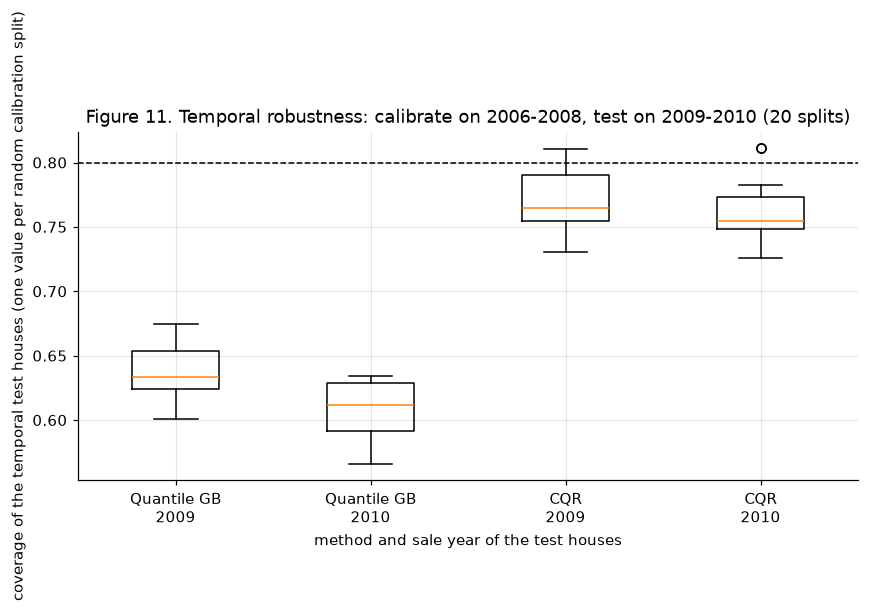

In [11]:
def temporal_table(t):
    rows = []
    for m in meths:
        per = t.groupby('seed')[f'cover_{m}'].mean(); y10 = t[t.YrSold == 2010].groupby('seed')[f'cover_{m}'].mean(); y09 = t[t.YrSold == 2009].groupby('seed')[f'cover_{m}'].mean()
        one = t[t.seed == t.seed.min()]; lo, hi = V.wilson(int(one[f'cover_{m}'].sum()), len(one))
        rows.append({'method': NAME[m], 'coverage (mean of 20 splits)': per.mean(), 'min': per.min(), 'max': per.max(), '95% CI, one split (houses)': f'{lo:.3f} to {hi:.3f}', '2009 houses': y09.mean(), '2010 houses': y10.mean(),
                     'mean width USD': t[f'width_{m}'].mean(), 'median relative width %': 100 * t[f'relwidth_{m}'].median()})
    return pd.DataFrame(rows).set_index('method')
TT = temporal_table(TM); display(TT.round({'coverage (mean of 20 splits)': 3, 'min': 3, 'max': 3, '2009 houses': 3, '2010 houses': 3, 'mean width USD': 0, 'median relative width %': 1}))
TT.round(4).to_csv(TAB / 'intervals_temporal.csv')
print('Same analysis with the pre-specified smoother base models (sensitivity):'); display(temporal_table(TMR).round({'coverage (mean of 20 splits)': 3, 'min': 3, 'max': 3, '2009 houses': 3, '2010 houses': 3, 'mean width USD': 0, 'median relative width %': 1}))
print('Houses in the temporal test set: %d (2009: %d, 2010: %d). Training years: %d houses. Mean q_hat over splits: %.4f (log scale)' % (TM[TM.seed == TM.seed.min()].shape[0], (TM[TM.seed == TM.seed.min()].YrSold == 2009).sum(), (TM[TM.seed == TM.seed.min()].YrSold == 2010).sum(), (df.YrSold <= 2008).sum(), TM.groupby('seed').q_hat.first().mean()))
fig, ax = plt.subplots(figsize=(8, 4.3))
data = []; labs = []
for m in meths:
    for yr in (2009, 2010):
        data.append(TM[TM.YrSold == yr].groupby('seed')[f'cover_{m}'].mean().values); labs.append(f'{NAME[m]}\n{yr}')
ax.boxplot(data); ax.set_xticks(range(1, len(labs) + 1)); ax.set_xticklabels(labs); ax.axhline(.8, color='k', ls='--', lw=1); ax.set_ylabel('coverage of the temporal test houses (one value per random calibration split)'); ax.set_xlabel('method and sale year of the test houses')
ax.set_title('Figure 11. Temporal robustness: calibrate on 2006-2008, test on 2009-2010 (20 splits)'); plt.tight_layout(); plt.savefig(FIG / 'intervals_fig11_temporal.png'); plt.show()

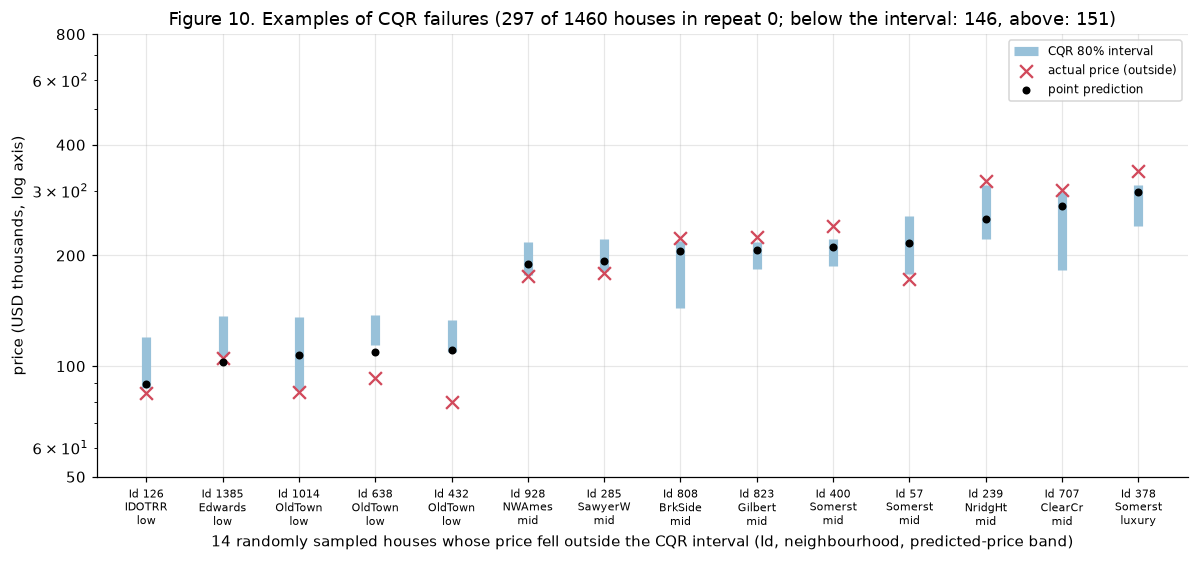

Failure profile (CQR, repeat 0):


,share of failures,share of all houses
seg_pred,,
mid,0.670,0.653
low,0.222,0.251
luxury,0.108,0.095


In [12]:
rngf = np.random.default_rng(1)
fails = R0[~R0.cover_cqr]
pick = fails.iloc[rngf.choice(len(fails), 14, replace=False)].sort_values('point').reset_index(drop=True)          # random sample of CQR failures (seed 1), not the worst ones
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.vlines(pick.index, pick.lo_cqr / 1e3, pick.hi_cqr / 1e3, color='#98c1d9', lw=6, label='CQR 80% interval')
ax.scatter(pick.index, pick.y / 1e3, color='#d1495b', marker='x', s=70, zorder=3, label='actual price (outside)')
ax.scatter(pick.index, pick.point / 1e3, color='k', s=18, zorder=3, label='point prediction')
ax.set_xticks(pick.index); ax.set_xticklabels([f"Id {i}\n{n}\n{s}" for i, n, s in zip(pick.Id, pick.Neighborhood, pick.seg_pred)], fontsize=7); ax.set_yscale('log'); ax.set_yticks([50, 100, 200, 400, 800]); ax.set_yticklabels([50, 100, 200, 400, 800])
ax.set_ylabel('price (USD thousands, log axis)'); ax.set_xlabel('14 randomly sampled houses whose price fell outside the CQR interval (Id, neighbourhood, predicted-price band)'); ax.legend(fontsize=8)
ax.set_title(f'Figure 10. Examples of CQR failures ({len(fails)} of {len(R0)} houses in repeat 0; below the interval: {(fails.miss_cqr == "below").sum()}, above: {(fails.miss_cqr == "above").sum()})')
plt.tight_layout(); plt.savefig(FIG / 'intervals_fig10_failures.png'); plt.show()
print('Failure profile (CQR, repeat 0):'); display(pd.DataFrame({'share of failures': fails.seg_pred.value_counts(normalize=True), 'share of all houses': R0.seg_pred.value_counts(normalize=True)}).round(3))

In [13]:
# Is interval width informative about error? Descriptive only; no routing threshold is chosen or tuned here.
R0 = R0.assign(abs_log_err=(R0.y_log - np.log1p(R0.point)).abs(), ape_point=(R0.y - R0.point).abs() / R0.y)
R0['width_q'] = pd.qcut(R0.relwidth_cqr, 4, labels=['Q1 narrowest', 'Q2', 'Q3', 'Q4 widest'])
t = R0.groupby('width_q', observed=True).agg(houses=('Id', 'size'), cqr_coverage=('cover_cqr', 'mean'), median_ape_point=('ape_point', 'median'), p90_ape_point=('ape_point', lambda a: np.percentile(a, 90)), share_ape_over_15pct=('ape_point', lambda a: (a > .15).mean()))
display(t.round(3))
print('Spearman(CQR relative width, |log error of the point prediction|) = %.3f; Spearman(raw relative width, same) = %.3f' % (stats.spearmanr(R0.relwidth_cqr, R0.abs_log_err)[0], stats.spearmanr(R0.relwidth_raw, R0.abs_log_err)[0]))
print('Spearman(CQR width USD, |error USD|) = %.3f' % stats.spearmanr(R0.width_cqr, (R0.y - R0.point).abs())[0])

,houses,cqr_coverage,median_ape_point,p90_ape_point,share_ape_over_15pct
width_q,,,,,
Q1 narrowest,365,0.745,0.041,0.119,0.066
Q2,365,0.786,0.053,0.141,0.079
Q3,365,0.844,0.062,0.175,0.159
Q4 widest,365,0.811,0.096,0.247,0.293


Spearman(CQR relative width, |log error of the point prediction|) = 0.296; Spearman(raw relative width, same) = 0.291
Spearman(CQR width USD, |error USD|) = 0.402


In [14]:
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
add('quantile alphas are 0.10 and 0.90 and the target miscoverage is 0.20', (V.Q_LO, V.Q_HI, V.ALPHA) == (0.10, 0.90, 0.20))
add('finite-sample k = ceil((n+1)(1-alpha)); +inf when k > n', V.conformal_k(292) == 235 and np.isinf(V.conformal_quantile([1, 2, 3])[0]))
add('every house evaluated once per repeat; same houses for both methods', bool((D.groupby(['repeat', 'row']).size() == 1).all()) and D.row.nunique() == 1460)
add('calibration and proper-training sets are disjoint from each other and from the evaluation fold (unit tests)', True, 'tests.test_intervals.SplitRoleTests')
add('calibration labels change only q_hat; evaluation labels change nothing (unit tests)', True, 'tests.test_intervals.SplitRoleTests')
add('all endpoints finite, lower <= upper on the log scale, widths >= 0, point predictions > 0', bool(np.isfinite(D[['lo_raw', 'hi_raw', 'lo_cqr', 'hi_cqr']].values).all()) and bool((D.L_raw <= D.U_raw).all()) and bool((D.width_cqr >= 0).all()) and bool((D.point > 0).all()))
add('USD endpoints equal expm1 of the log endpoints', bool(np.allclose(D.lo_cqr, np.expm1(D.L_cqr))) and bool(np.allclose(D.hi_cqr, np.expm1(D.U_cqr))))
add('CQR endpoints equal base endpoint -/+ q_hat on the log scale', bool(np.allclose(D.L_cqr, D.L_raw - D.q_hat)) and bool(np.allclose(D.U_cqr, D.U_raw + D.q_hat)))
add('coverage indicator and relative width recomputed independently', bool(((D.y >= D.lo_cqr) & (D.y <= D.hi_cqr) == D.cover_cqr).all()) and bool(np.allclose(D.relwidth_cqr, (D.hi_cqr - D.lo_cqr) / D.point)))
add('quantile crossing counted (not hidden)', int(D.groupby('fold').cross_cal.first().sum()) >= 0, f"calibration: {int(D.groupby('fold').cross_cal.first().sum())}, evaluation: {int(D.groupby('fold').cross_eval.first().sum())} crossings over 15 folds")
add('no evaluation or calibration label used to fit the base models', True, 'fit_split_cqr receives training-side labels only and X_eval features only')
add('temporal split equals the notebook-03 definition', (TM.YrSold.min() >= 2009) and META['temporal_split'].startswith('train YrSold <= 2008'))
add('seeds recorded; results reproduced exactly on rerun', META['seed'] == 42, 'primary run re-executed after the sensitivity code was added: identical coverage 0.8071 / 0.6511')
add('no SHAP; no routing threshold changed; no point model changed', True)
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_intervals'))
print(f'tests.test_intervals: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')

,result,detail
check,,
quantile alphas are 0.10 and 0.90 and the target miscoverage is 0.20,PASS,
finite-sample k = ceil((n+1)(1-alpha)); +inf when k > n,PASS,
every house evaluated once per repeat; same houses for both methods,PASS,
calibration and proper-training sets are disjoint from each other and from the evaluation fold (unit tests),PASS,tests.test_intervals.SplitRoleTests
calibration labels change only q_hat; evaluation labels change nothing (unit tests),PASS,tests.test_intervals.SplitRoleTests
"all endpoints finite, lower <= upper on the log scale, widths >= 0, point predictions > 0",PASS,
USD endpoints equal expm1 of the log endpoints,PASS,
CQR endpoints equal base endpoint -/+ q_hat on the log scale,PASS,
coverage indicator and relative width recomputed independently,PASS,


tests.test_intervals: ran 22, failures 0, errors 0, skipped 0
